# 02 — Exploratory Data Analysis (EDA)

Inspects `data/processed/{train,validate,test}/{healthy,parkinson}` after dataset audit & MD5 deduplication:
- Overall and split-wise class distribution & imbalance ratio
- Image dimensions, channels, and aspect ratios
- Random sample visual grid
- Training pixel intensity distribution (checking for brightness/background shortcuts)

All outputs and charts are also saved under `reports/eda/` for reporting or UI integration.**Usage:** Run all cells after activating the `parkinsons` Conda environment. This notebook generates and saves EDA plots and `eda_summary.json` under `reports/eda/`

In [1]:
import json
import sys
from pathlib import Path
from IPython.display import Image as IPyImage, display

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from configs.config import EDA_REPORTS_DIR, PROCESSED_DATA_DIR, ensure_project_dirs
from src.data.eda import load_processed_dataframe, run_eda

ensure_project_dirs()
df = load_processed_dataframe(PROCESSED_DATA_DIR)
print(f"Loaded {len(df)} processed images.")
df.head()

Loaded 831 processed images.


,path,split,label,width,height,aspect_ratio,channels,format
0,/Users/aadhi/Parkinson's Detection/parkinsons-...,train,healthy,250,320,0.78125,3,PNG
1,/Users/aadhi/Parkinson's Detection/parkinsons-...,train,healthy,250,320,0.78125,3,PNG
2,/Users/aadhi/Parkinson's Detection/parkinsons-...,train,healthy,250,320,0.78125,3,PNG
3,/Users/aadhi/Parkinson's Detection/parkinsons-...,train,healthy,250,320,0.78125,3,PNG
4,/Users/aadhi/Parkinson's Detection/parkinsons-...,train,healthy,250,320,0.78125,3,PNG


In [2]:
summary = run_eda(processed_dir=PROCESSED_DATA_DIR, output_dir=EDA_REPORTS_DIR)
summary_path = EDA_REPORTS_DIR / "eda_summary.json"
summary_json = json.dumps(summary, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o))
summary_path.write_text(summary_json, encoding="utf-8")
print(summary_json)

{
  "total_images": 831,
  "overall_counts": {
    "healthy": 610,
    "parkinson": 221
  },
  "split_counts": {
    "healthy": {
      "test": 92,
      "train": 426,
      "validate": 92
    },
    "parkinson": {
      "test": 33,
      "train": 155,
      "validate": 33
    }
  },
  "imbalance_ratio": 2.76,
  "unique_channels": [
    3
  ],
  "width_summary": {
    "count": 831.0,
    "mean": 236.57,
    "std": 70.96,
    "min": 128.0,
    "25%": 232.0,
    "50%": 250.0,
    "75%": 250.0,
    "max": 560.0
  },
  "height_summary": {
    "count": 831.0,
    "mean": 270.52,
    "std": 86.68,
    "min": 128.0,
    "25%": 256.0,
    "50%": 256.0,
    "75%": 320.0,
    "max": 560.0
  },
  "aspect_ratio_summary": {
    "count": 831.0,
    "mean": 0.893,
    "std": 0.095,
    "min": 0.781,
    "25%": 0.781,
    "50%": 0.906,
    "75%": 1.0,
    "max": 1.0
  },
  "intensity_stats": {
    "healthy": {
      "mean": 49.98300668917229,
      "std": 58.208117504974794
    },
    "parkinson": {
 

### Class Distribution & Image Dimensions

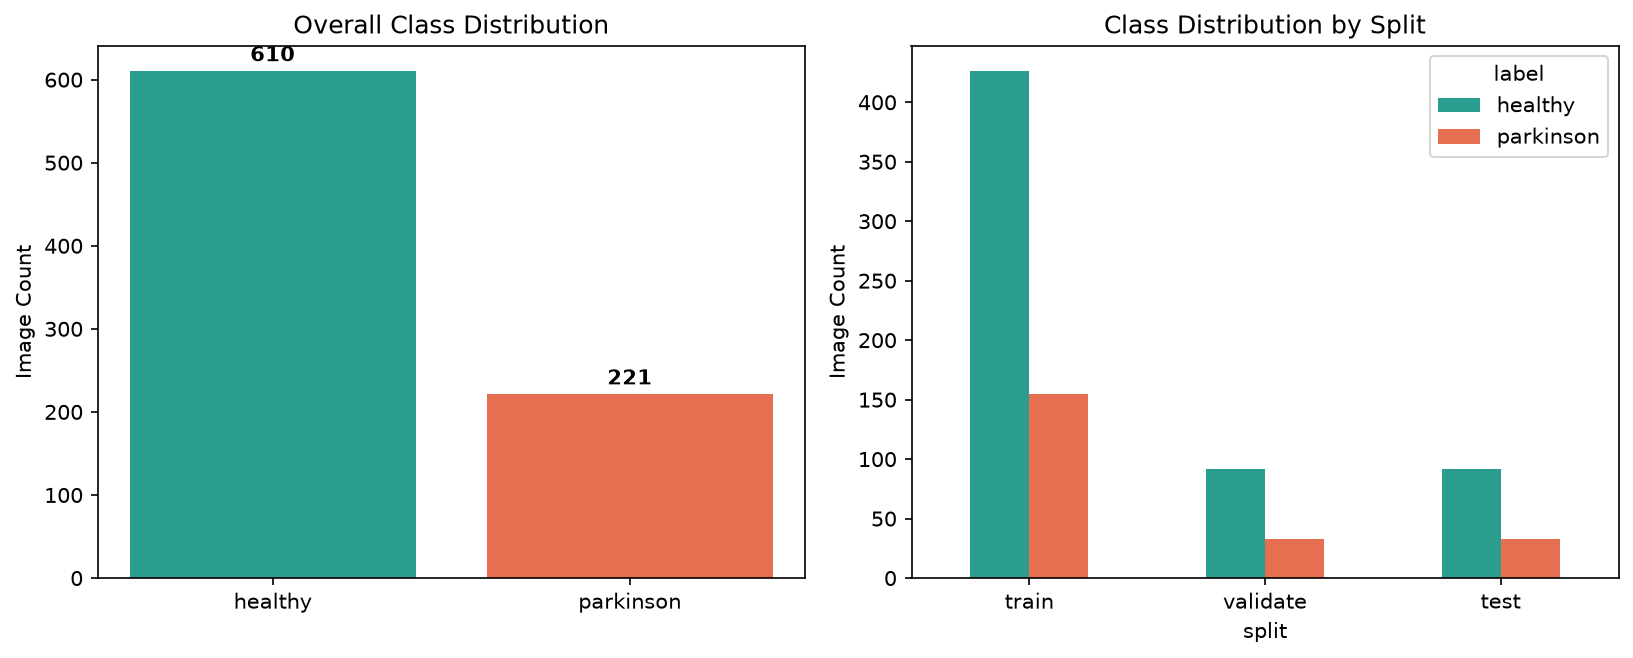

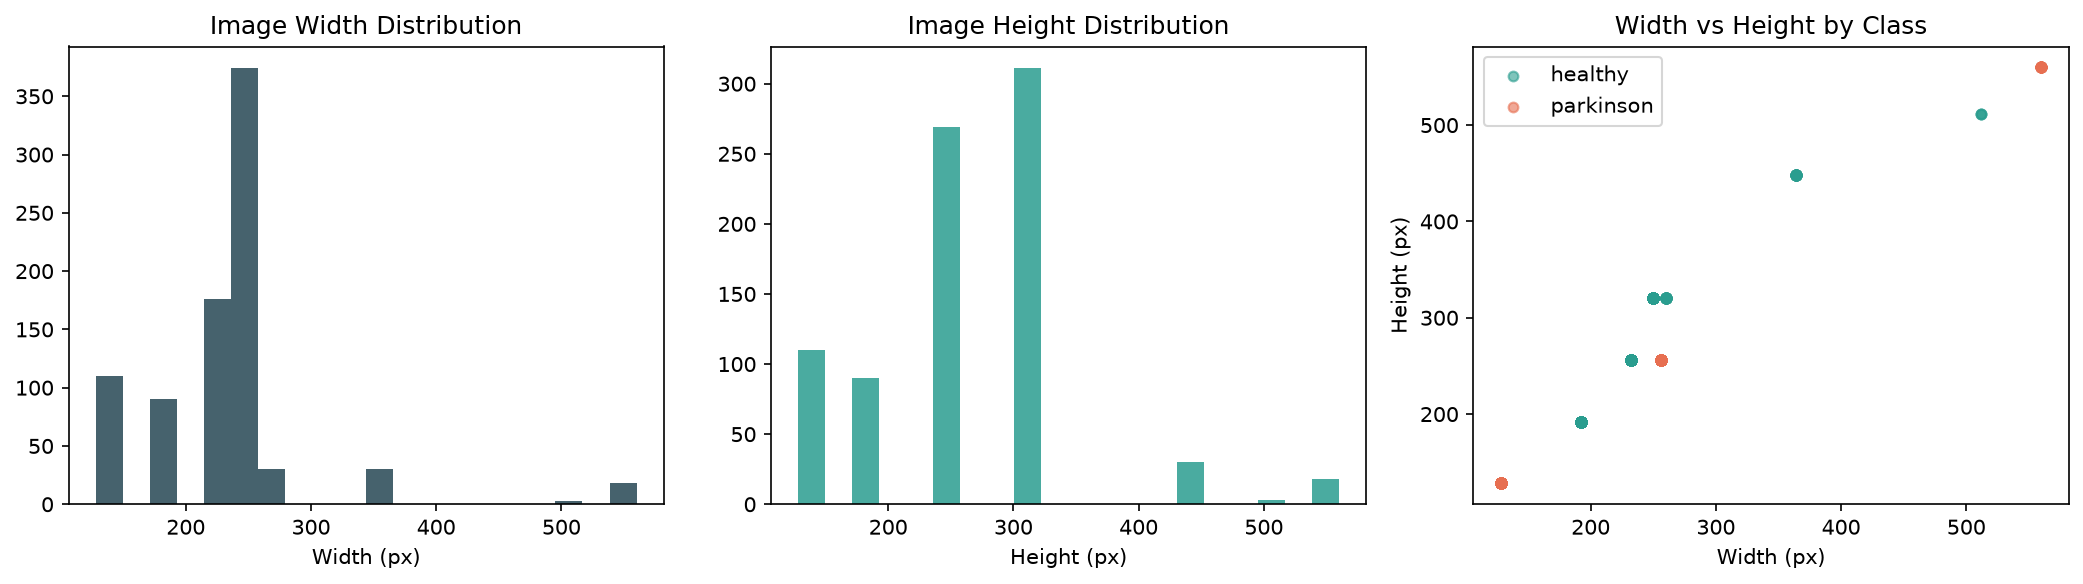

In [3]:
display(IPyImage(filename=summary["plots"]["class_distribution"]))
display(IPyImage(filename=summary["plots"]["image_dimensions"]))

### Sample Grid & Pixel Intensity Distribution (Shortcut Check)

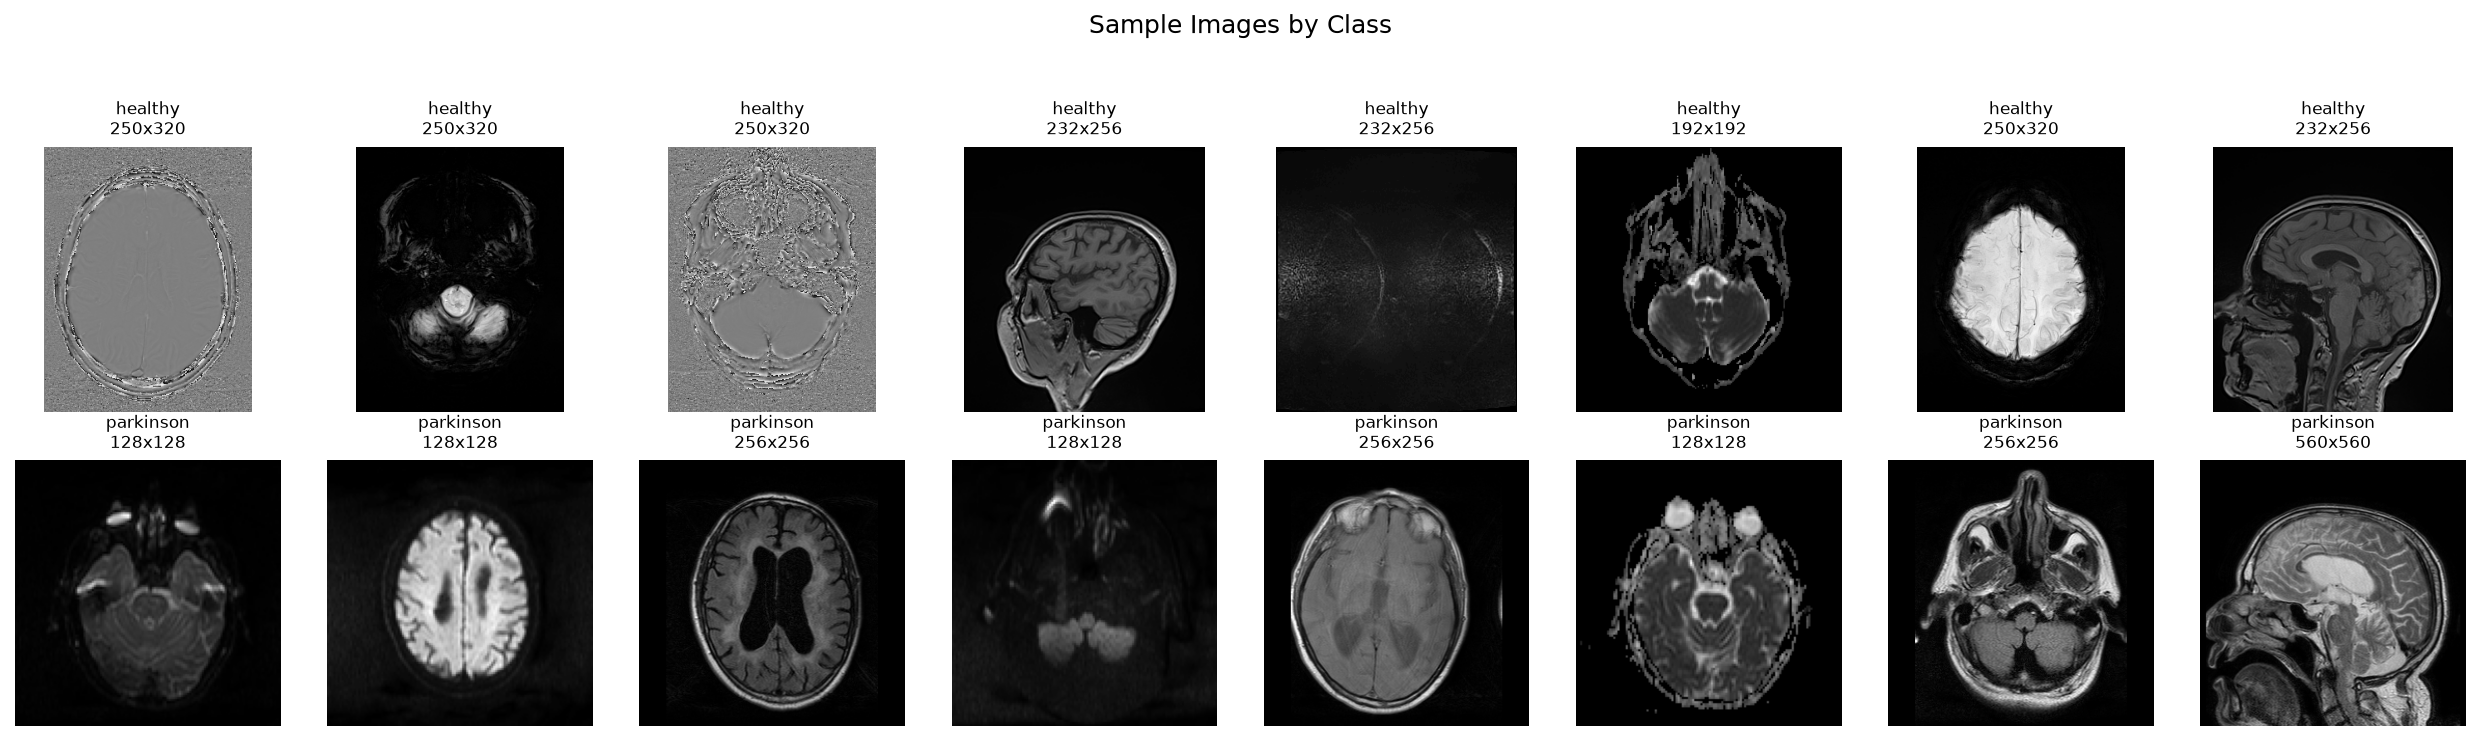

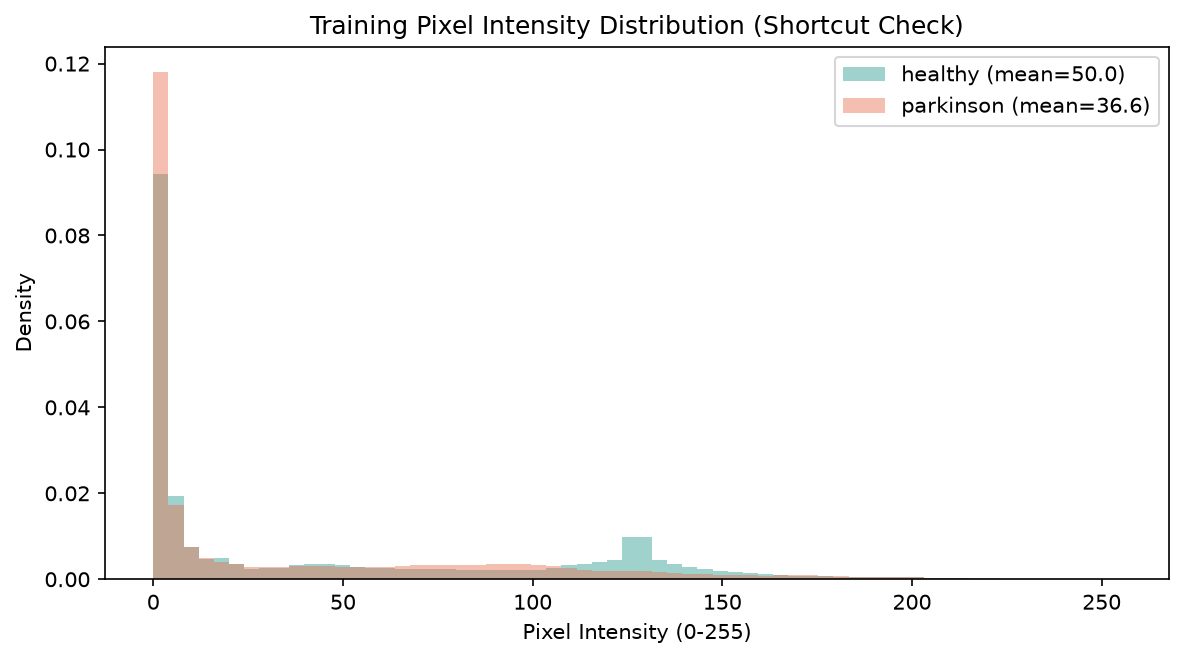

In [4]:
display(IPyImage(filename=summary["plots"]["sample_grid"]))
display(IPyImage(filename=summary["plots"]["intensity_distribution"]))